# Assignment 1 — Exploratory Data Analysis and Preprocessing

**Purpose:** Analyse the validated data and create leakage-safe model inputs for both architectures.

This notebook is an executable evidence view over the shared local pipeline. The
command-line runner and notebook call the same stage implementation, preventing code
drift. Completed artifacts are reused; no Google Colab or Google Drive runtime is used.


In [1]:
# Local WSL project bootstrap. Dependency installation belongs to the
# locked project environment and is intentionally not repeated in notebooks.
from pathlib import Path
import json
import os
import platform
import sys

candidate = Path.cwd().resolve()
PROJECT_ROOT = next(
    (path for path in [candidate, *candidate.parents] if (path / "shared").exists()),
    candidate,
)
if not (PROJECT_ROOT / "shared").exists():
    raise FileNotFoundError(
        "Open this notebook from the local odl-assignment project root."
    )
os.environ["ODL_PROJECT_ROOT"] = str(PROJECT_ROOT)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from shared.config import PATHS
from shared.runtime import RuntimeOptions
from shared.workflow import run_stage

OPTIONS = RuntimeOptions.from_environment()
print("Project root:", PROJECT_ROOT)
print("Run mode:", OPTIONS.mode)
print("Device policy:", OPTIONS.device)
print("WSL distribution:", os.getenv("WSL_DISTRO_NAME", "not detected"))


I0000 00:00:1786699771.773498   26746 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Project root: /home/nicholas/code/odl-assignment
Run mode: full
Device policy: gpu
WSL distribution: Ubuntu-24.04


I0000 00:00:1786699772.827808   26746 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


In [2]:
# Run the shared stage or load its verified completed result.
STAGE_SUMMARY = run_stage("prepare", options=OPTIONS)
STAGE_SUMMARY


{'rows': 359712,
 'features': 41,
 'split_counts': {'train': 292006, 'validation': 59962, 'test': 0},
 'sequence_shape': [4, 12, 41],
 'target_shape': [4, 1],
 'run_mode': 'full'}

In [3]:
# Record the exact runtime used for this output when preflight evidence exists.
environment_path = PATHS.environment_artifacts / f"environment_{OPTIONS.mode}.json"
ENVIRONMENT = (
    json.loads(environment_path.read_text(encoding="utf-8"))
    if environment_path.exists()
    else {"status": "preflight evidence not yet generated"}
)
ENVIRONMENT


{'captured_at_utc': '2026-08-14T09:29:07.880963+00:00',
 'project_root': '/home/nicholas/code/odl-assignment',
 'platform': 'Linux-6.6.87.2-microsoft-standard-WSL2-x86_64-with-glibc2.39',
 'system': 'Linux',
 'release': '6.6.87.2-microsoft-standard-WSL2',
 'python': '3.12.3',
 'wsl_distribution': 'Ubuntu-24.04',
 'device': 'gpu',
 'tensorflow_gpu_devices': ['/physical_device:GPU:0'],
 'batch_size': 256,
 'mixed_precision': False,
 'nvidia_smi': {'available': True,
  'name': 'NVIDIA GeForce RTX 3050 Laptop GPU',
  'driver_version': '591.74',
  'memory.total': '4096',
  'memory.used': '167',
  'utilization.gpu': '3',
  'temperature.gpu': '62',
  'power.draw': '18.49'},
 'packages': {'tensorflow': '2.21.0',
  'numpy': '2.3.5',
  'pandas': '2.3.3',
  'pyarrow': '25.0.0',
  'scikit-learn': '1.9.0',
  'matplotlib': '3.11.1',
  'seaborn': '0.13.2'},
 'git': {'available': True,
  'revision': '4e8a886f8c5ec31e376ce1fd0a256c49b441fea9',
  'dirty': True},
 'experiment_config': {'methodology_versi

## Distribution, missingness, and station differences

These outputs quantify the target's skew, extreme values, spatial variation, and the
length of missing runs before causal imputation.


,count,mean,std,min,1%,25%,50%,75%,99%,max
PM2.5,352112.0,78.851599,78.395881,2.0000,3.0000,21.0,55.0,110.0,356.0,999.0
PM10,354120.0,104.640754,89.665532,2.0000,5.0000,37.0,84.0,146.0,407.0,999.0
SO2,351743.0,16.709398,22.585074,0.2856,1.1424,3.0,8.0,21.0,107.0,500.0
NO2,348865.0,49.853606,34.525341,1.0265,2.0000,23.0,42.0,70.0,155.0,290.0
CO,340367.0,1193.788302,1095.766404,100.0000,100.0000,500.0,900.0,1500.0,5600.0,10000.0
O3,348044.0,60.516249,58.008628,0.2142,1.0000,13.0,48.0,86.0,249.0,1071.0
TEMP,359533.0,14.184745,11.316918,-19.9000,-8.0000,4.1,15.6,23.6,34.0,41.6
PRES,359532.0,1009.923856,10.387733,982.4000,990.2000,1001.5,1009.2,1018.0,1032.0,1042.8
DEWP,359528.0,2.902918,13.728139,-43.4000,-24.9000,-8.4,3.9,15.4,24.5,29.1
RAIN,359536.0,0.067360,0.841252,0.0000,0.0000,0.0,0.0,0.0,1.4,72.5


,station,column,missing_runs,maximum_run_hours,median_run_hours
40,Dongsi,CO,264,1517,1.0
28,Dingling,CO,284,1051,1.0
39,Dongsi,NO2,172,900,1.0
100,Shunyi,CO,649,749,1.0
124,Wanliu,CO,276,642,1.0
123,Wanliu,NO2,267,548,1.0
110,Tiantan,SO2,274,457,1.0
52,Guanyuan,CO,298,441,1.0
125,Wanliu,O3,695,429,1.0
99,Shunyi,NO2,391,423,1.0


,station,count,mean,median,std,min,max
0,Aotizhongxin,29110,81.995270,59.0,79.815643,3.0,898.0
1,Changping,29257,70.587114,47.0,70.580694,2.0,882.0
2,Dingling,29408,65.899786,41.0,71.994171,3.0,881.0
3,Dongsi,29341,84.492727,61.0,83.312179,3.0,737.0
4,Guanyuan,29459,81.701646,59.0,78.209933,3.0,680.0
5,Gucheng,29426,82.443288,60.0,79.065081,2.0,770.0
6,Huairou,29095,69.582128,47.0,70.126145,2.0,762.0
7,Nongzhanguan,29433,83.514151,59.0,83.629824,3.0,844.0
8,Shunyi,29208,78.701133,55.0,79.022319,3.0,941.0
9,Tiantan,29369,80.902850,59.0,78.153689,3.0,821.0


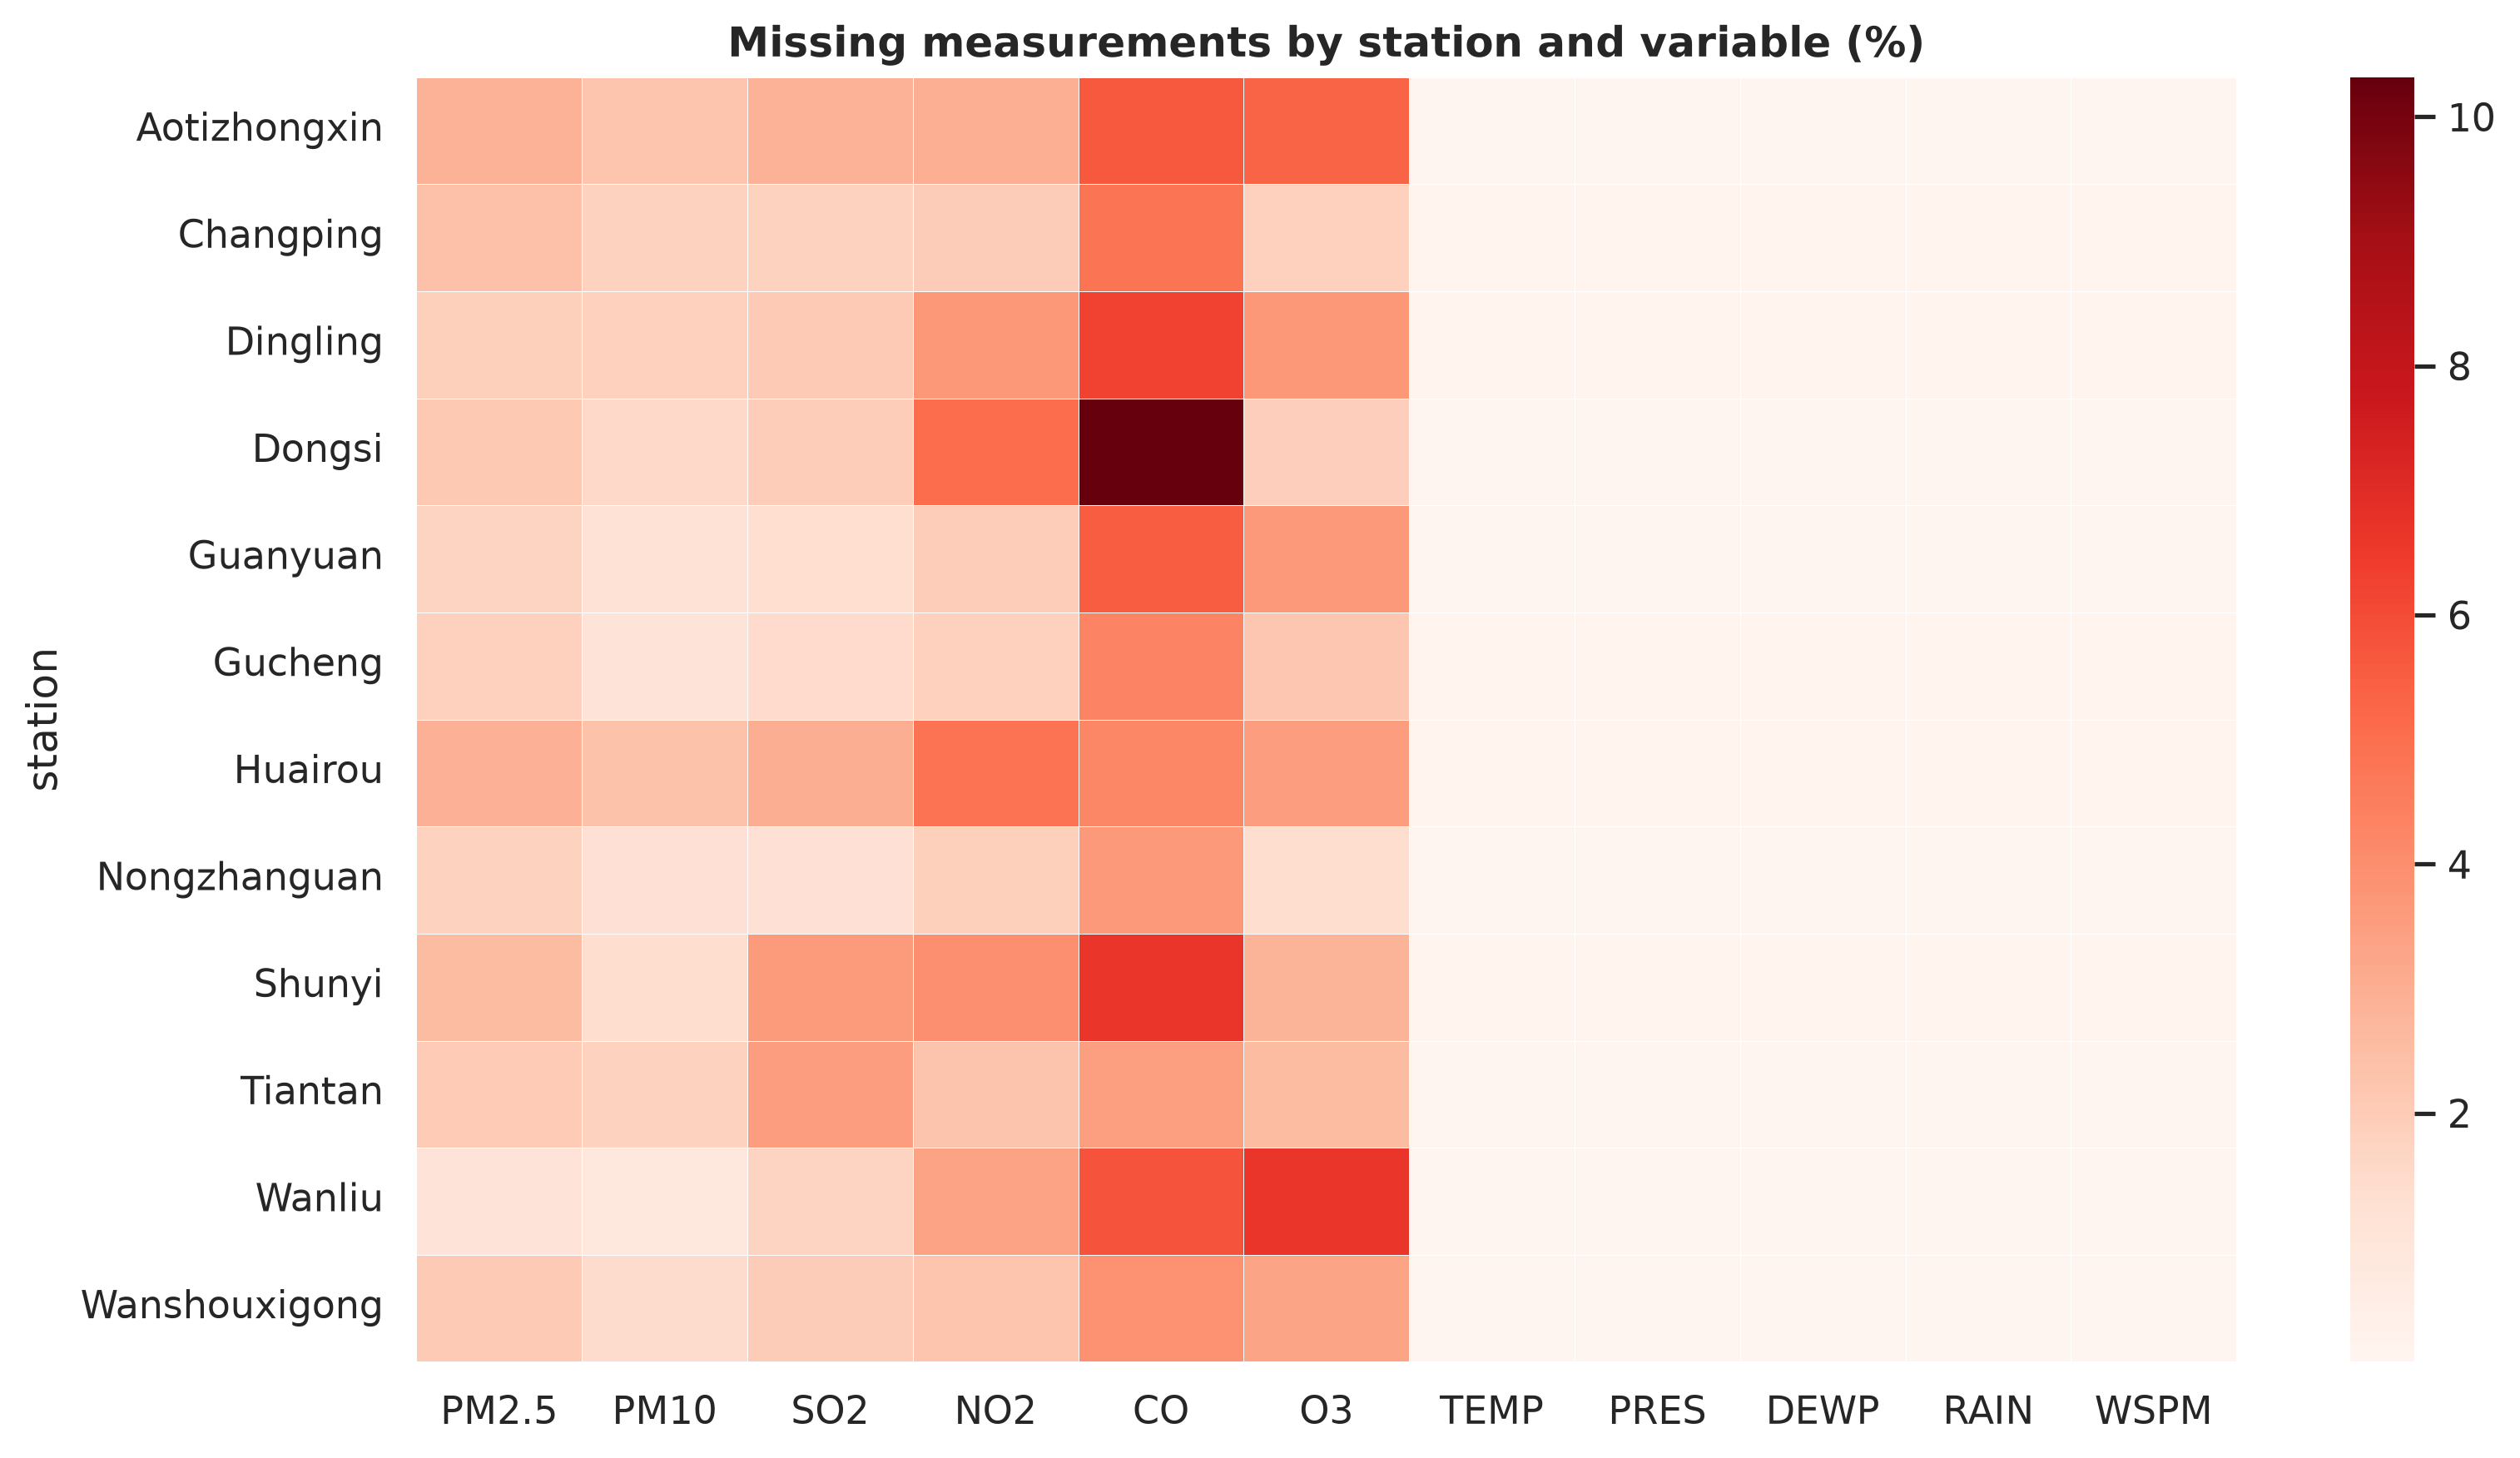

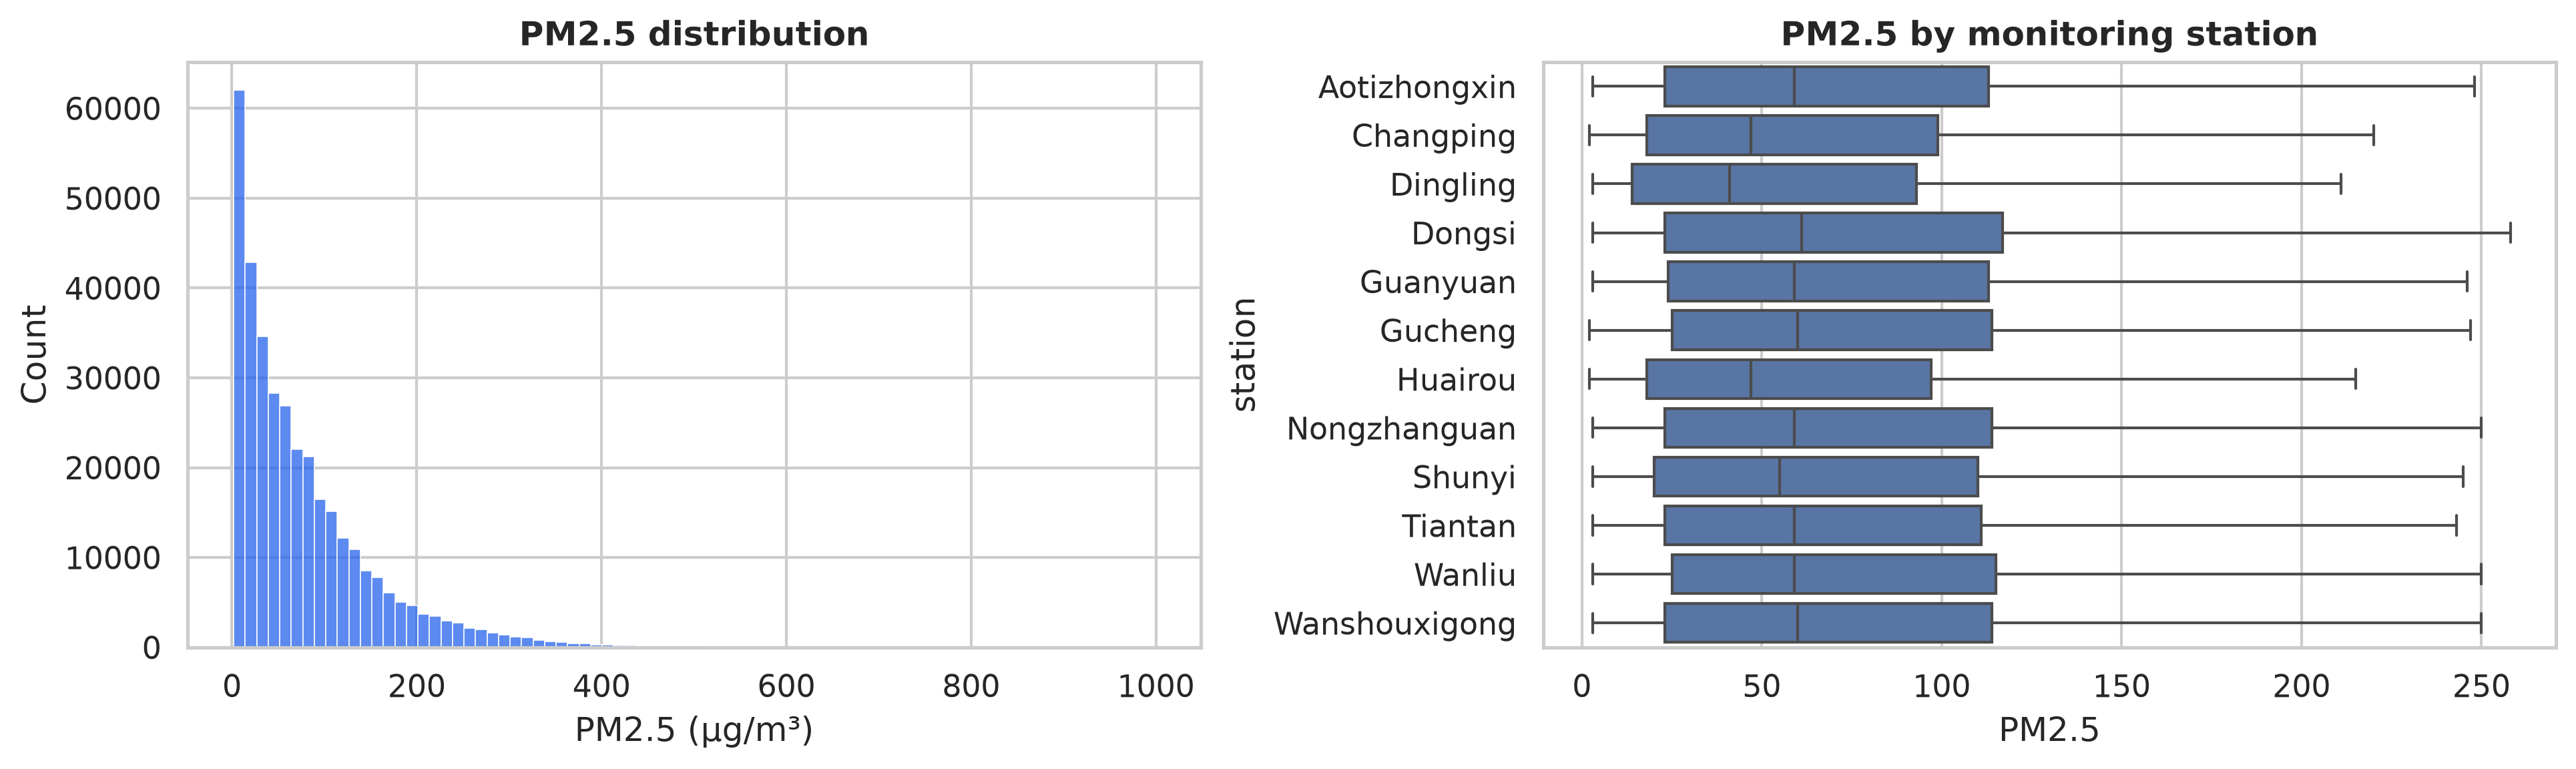

In [4]:
import pandas as pd
from IPython.display import Image, display

descriptive = pd.read_csv(
    PATHS.assignment1_tables / "descriptive_statistics.csv", index_col=0
)
missing_runs = pd.read_csv(PATHS.assignment1_tables / "missing_run_summary.csv")
station_statistics = pd.read_csv(
    PATHS.assignment1_tables / "pm25_station_statistics.csv"
)
display(descriptive)
display(missing_runs.sort_values("maximum_run_hours", ascending=False).head(20))
display(station_statistics)
display(Image(filename=str(PATHS.assignment1_figures / "missingness_heatmap.png")))
display(Image(filename=str(
    PATHS.assignment1_figures / "pm25_distribution_and_station_boxplots.png"
)))


## Temporal and feature relationships

Hourly/seasonal behaviour and autocorrelation justify cyclical features and testing
12-, 24-, and 48-hour lookbacks. The final lookback is selected only by rolling
validation; correlation and sampled scatter plots provide complementary evidence
about contemporaneous predictors.


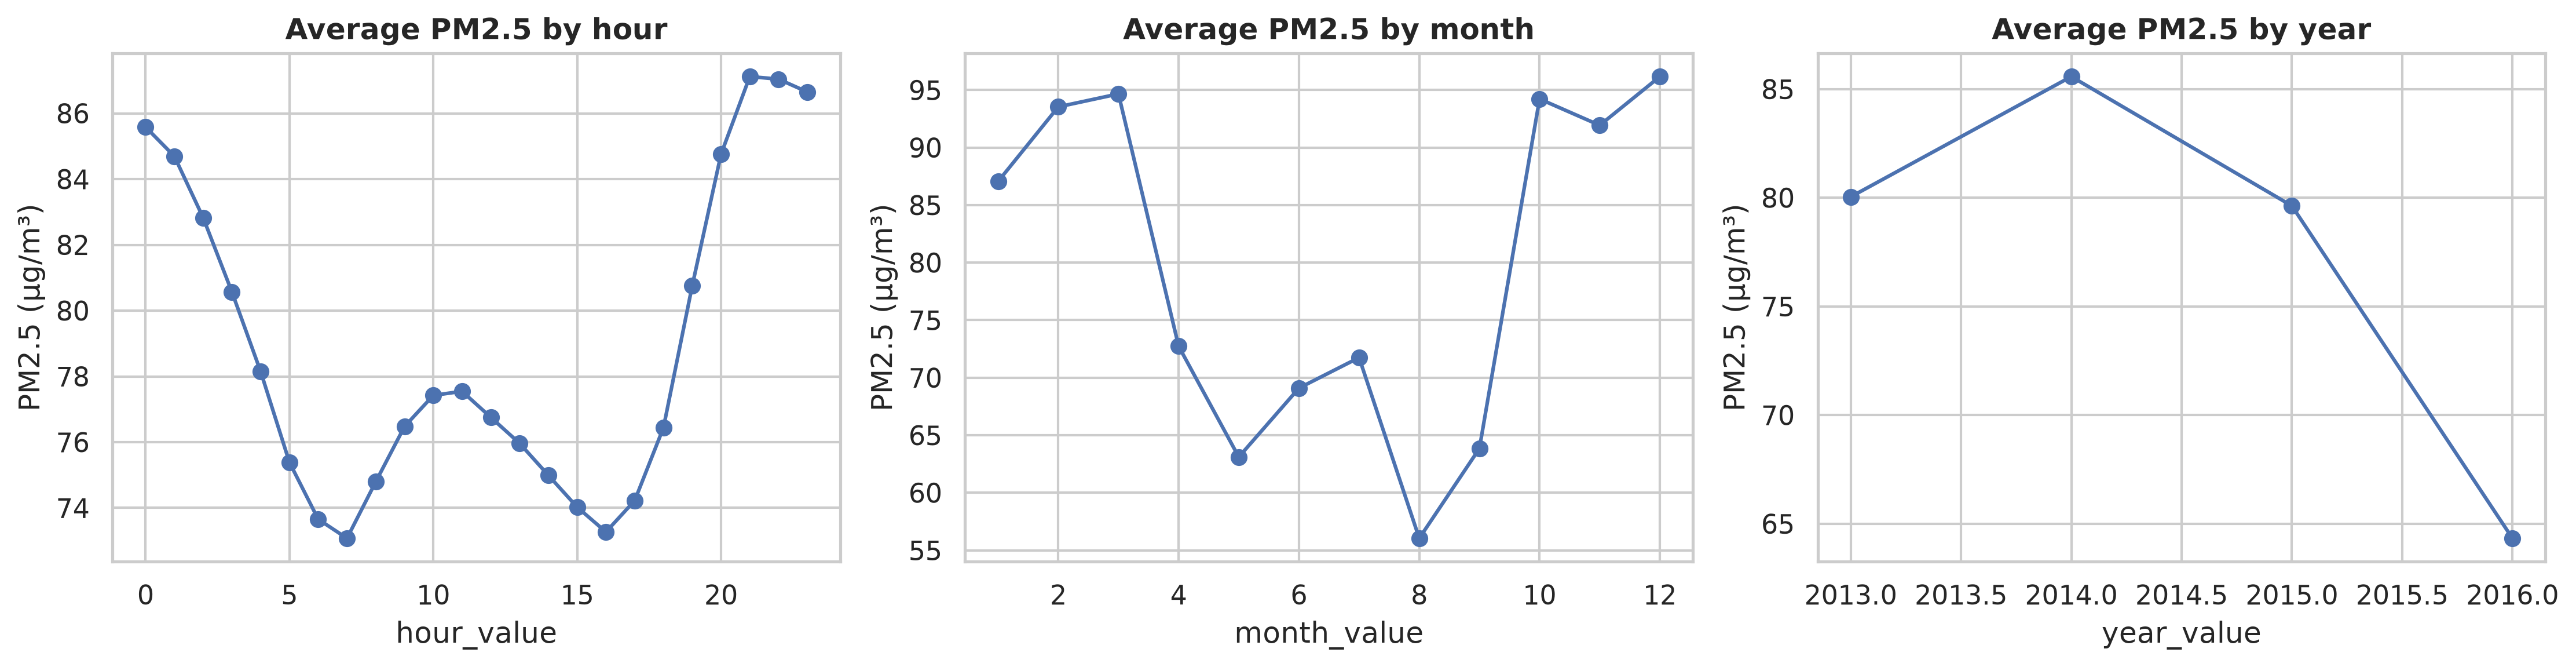

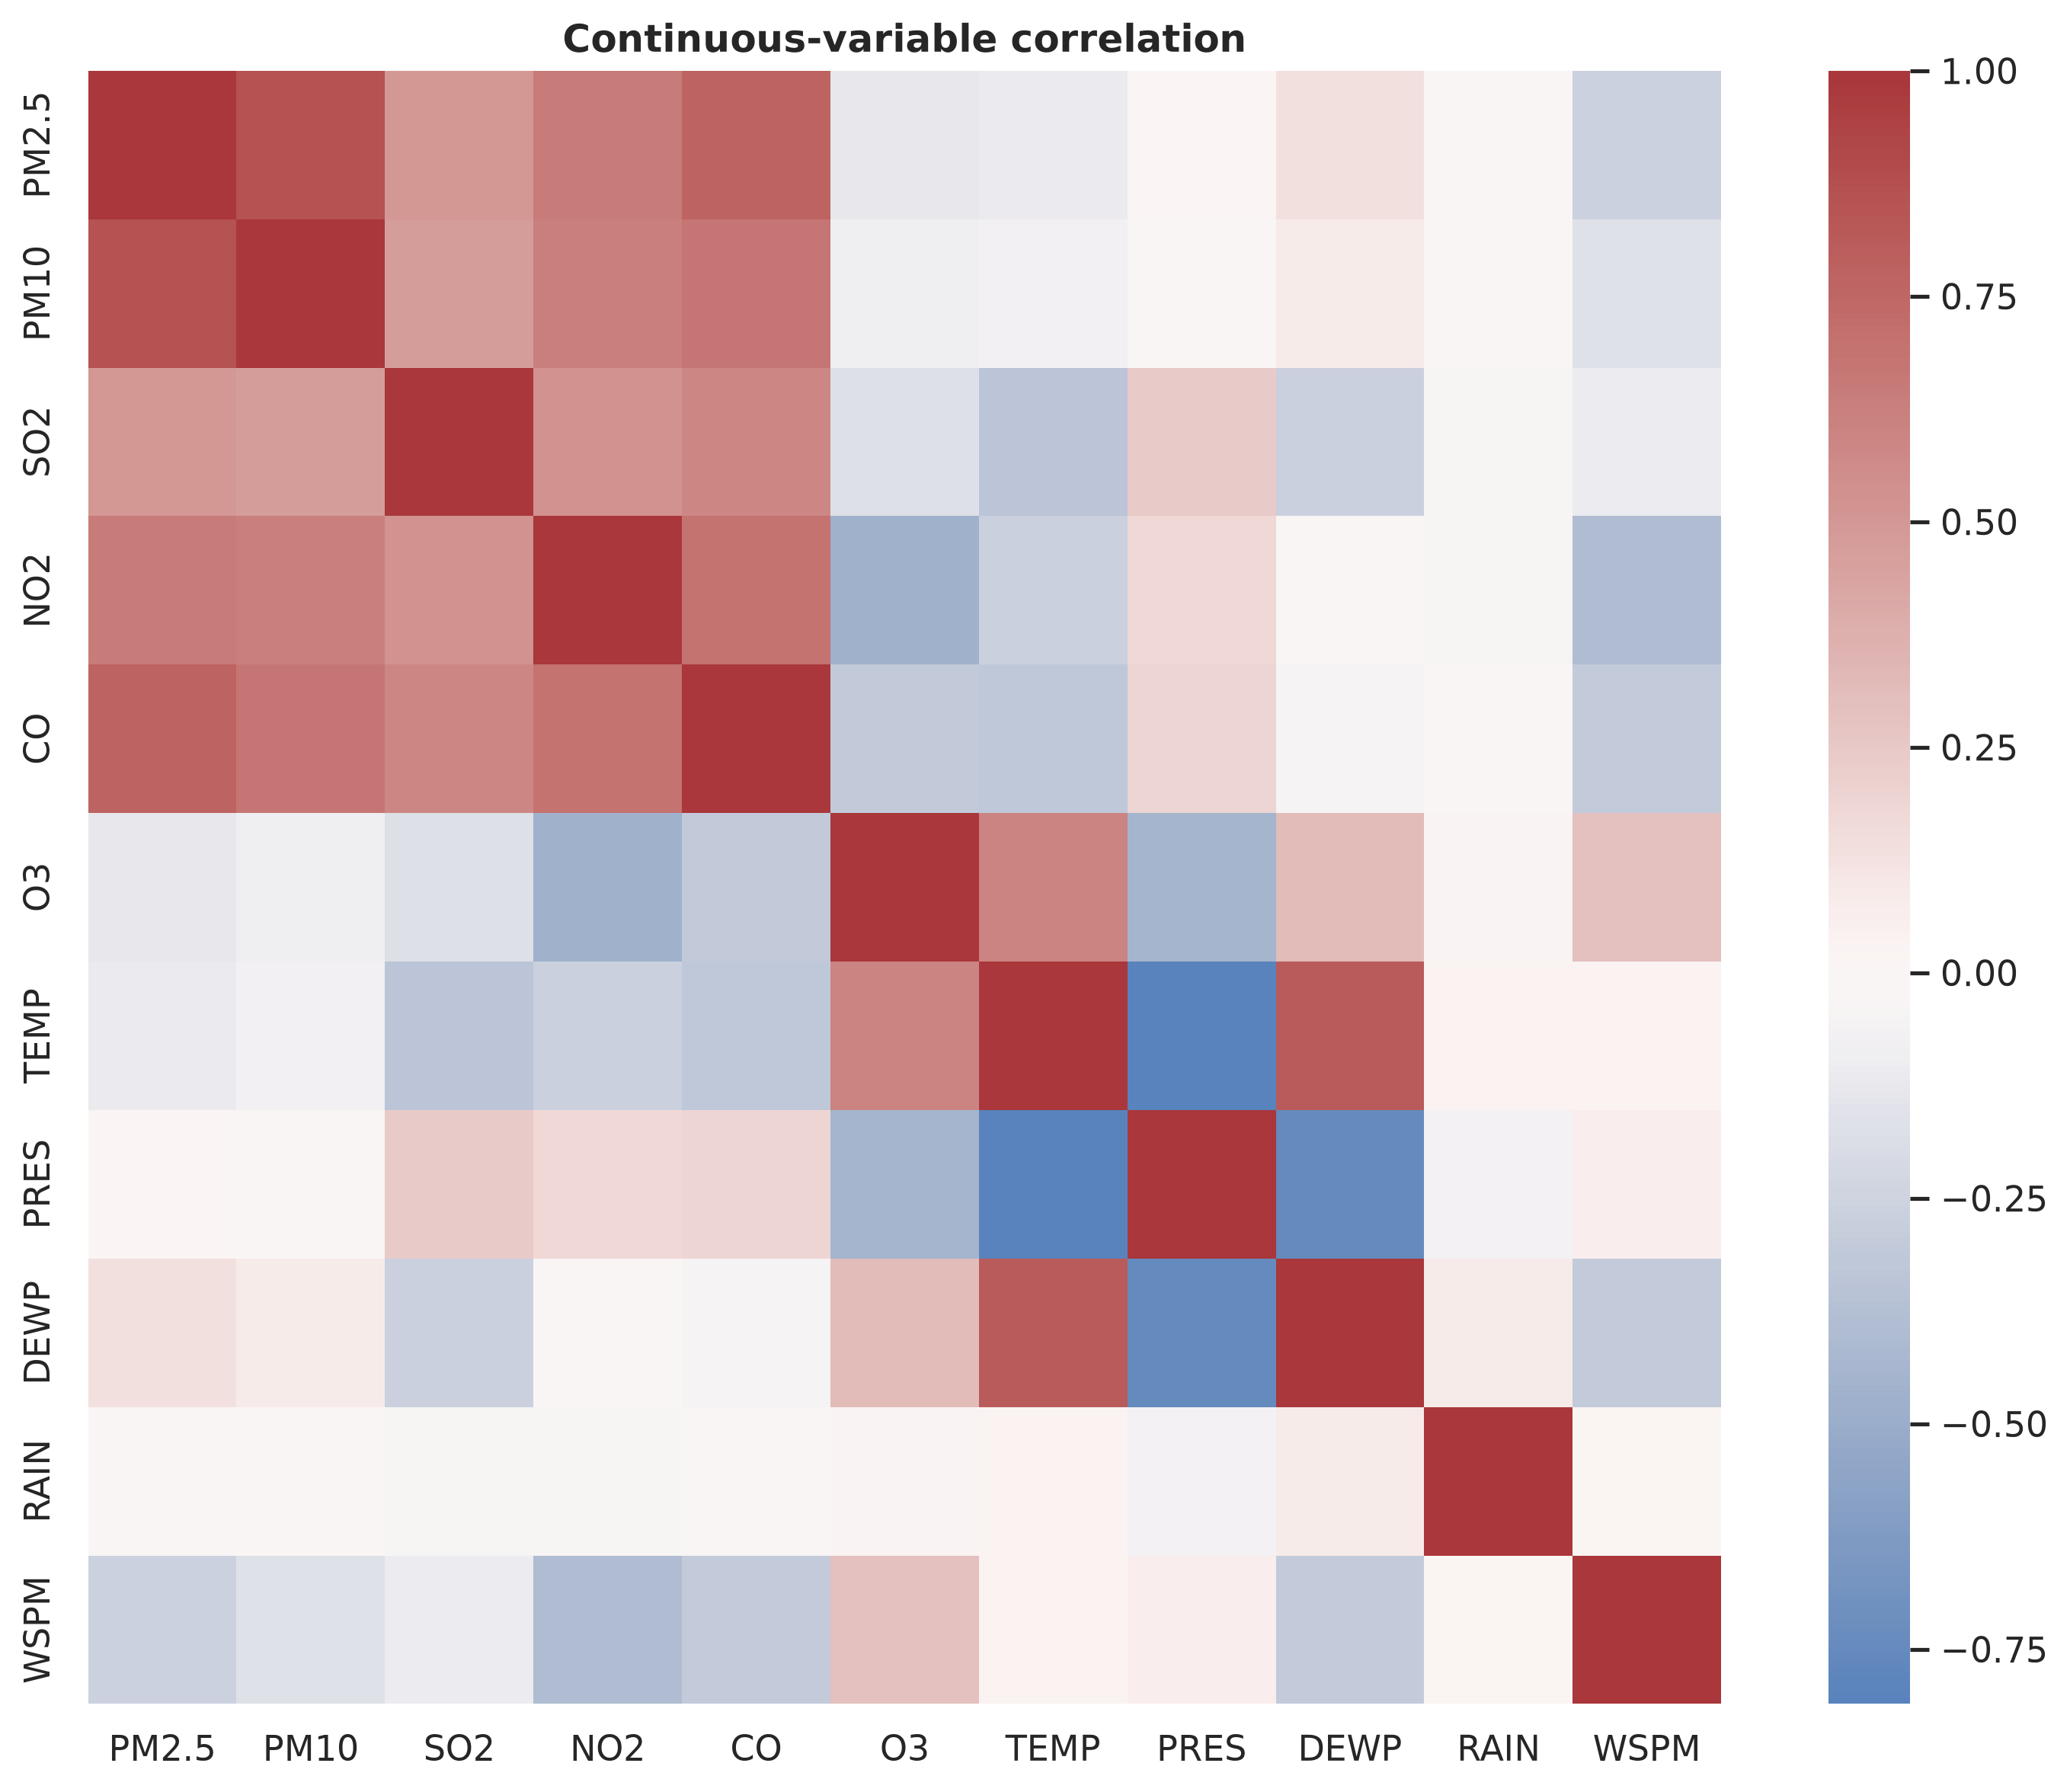

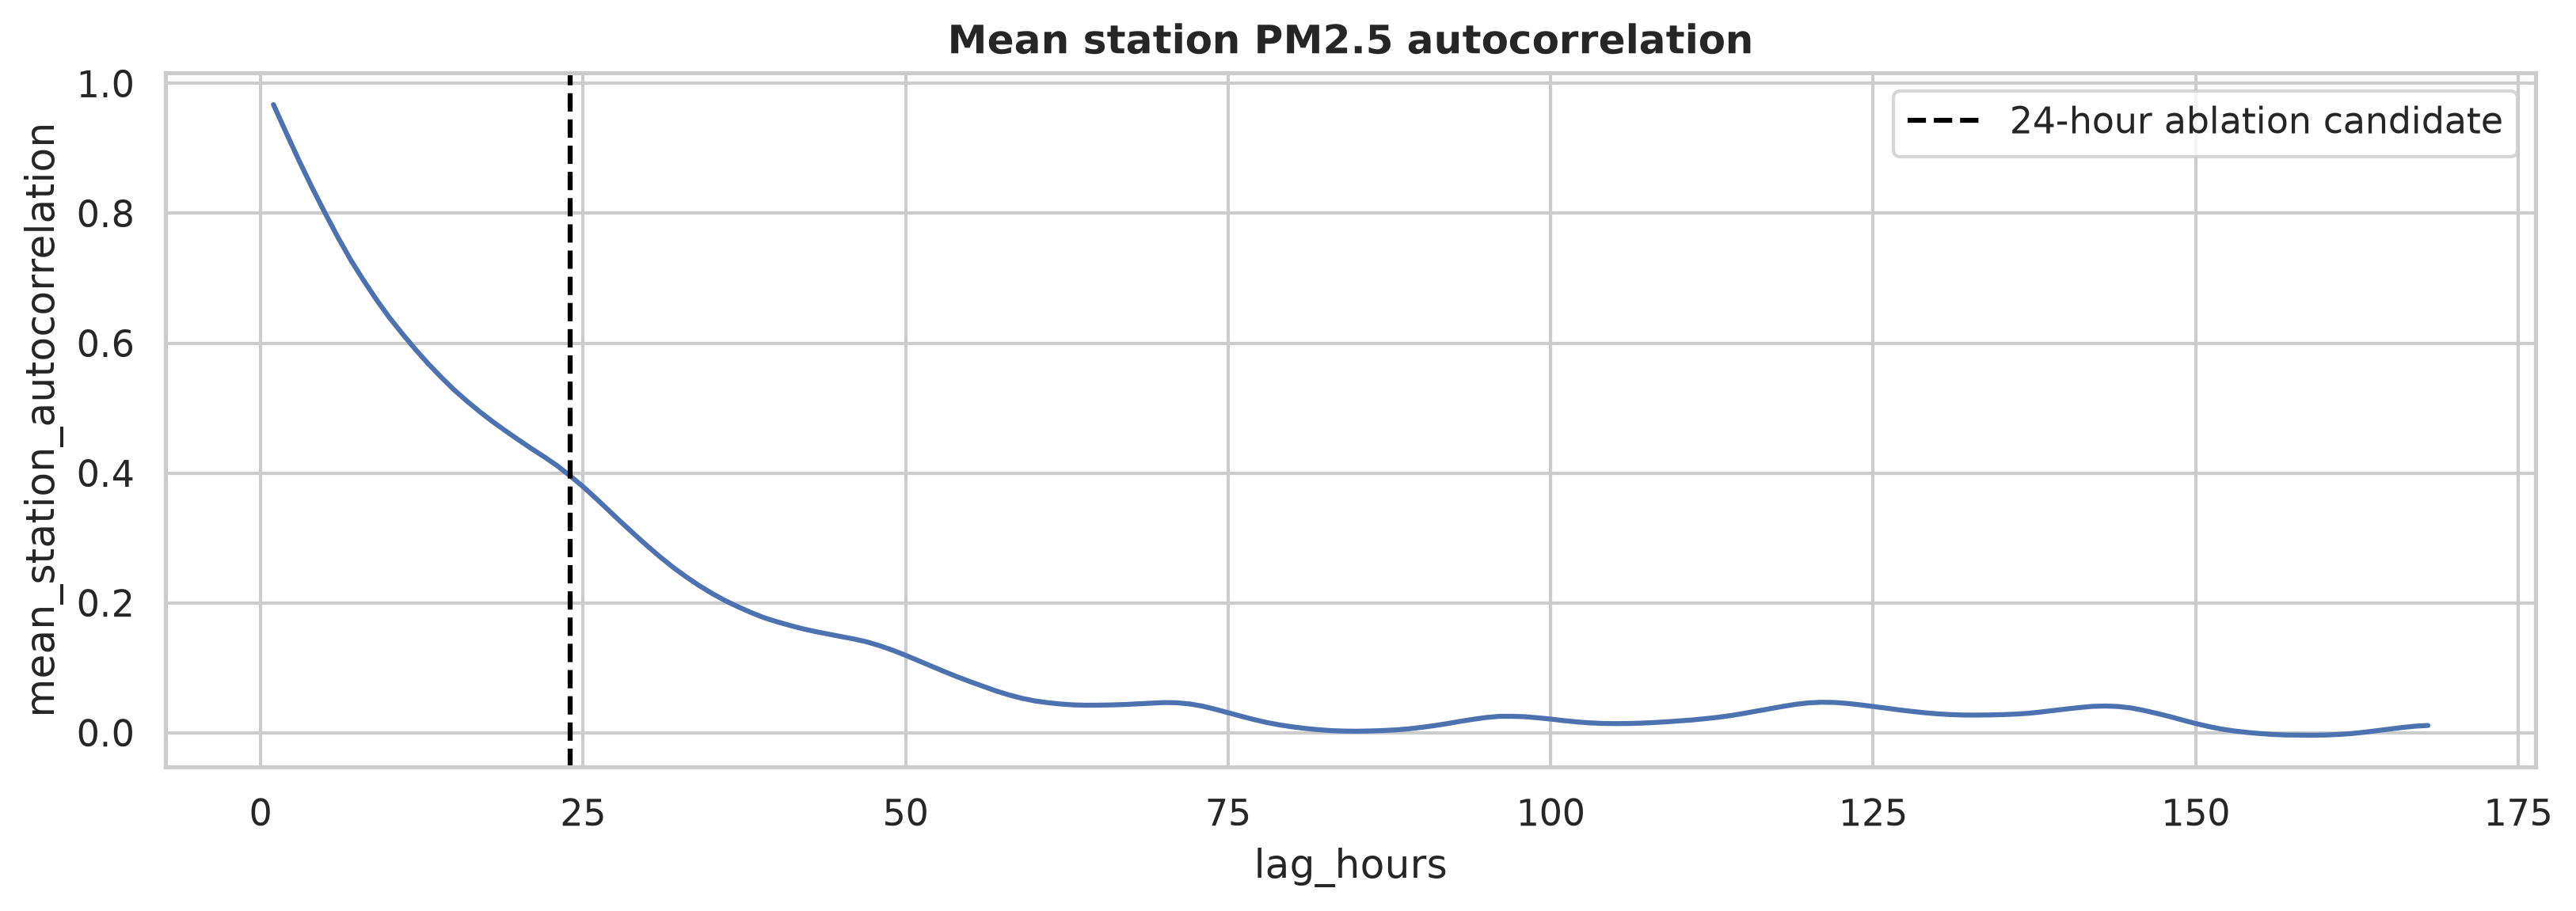

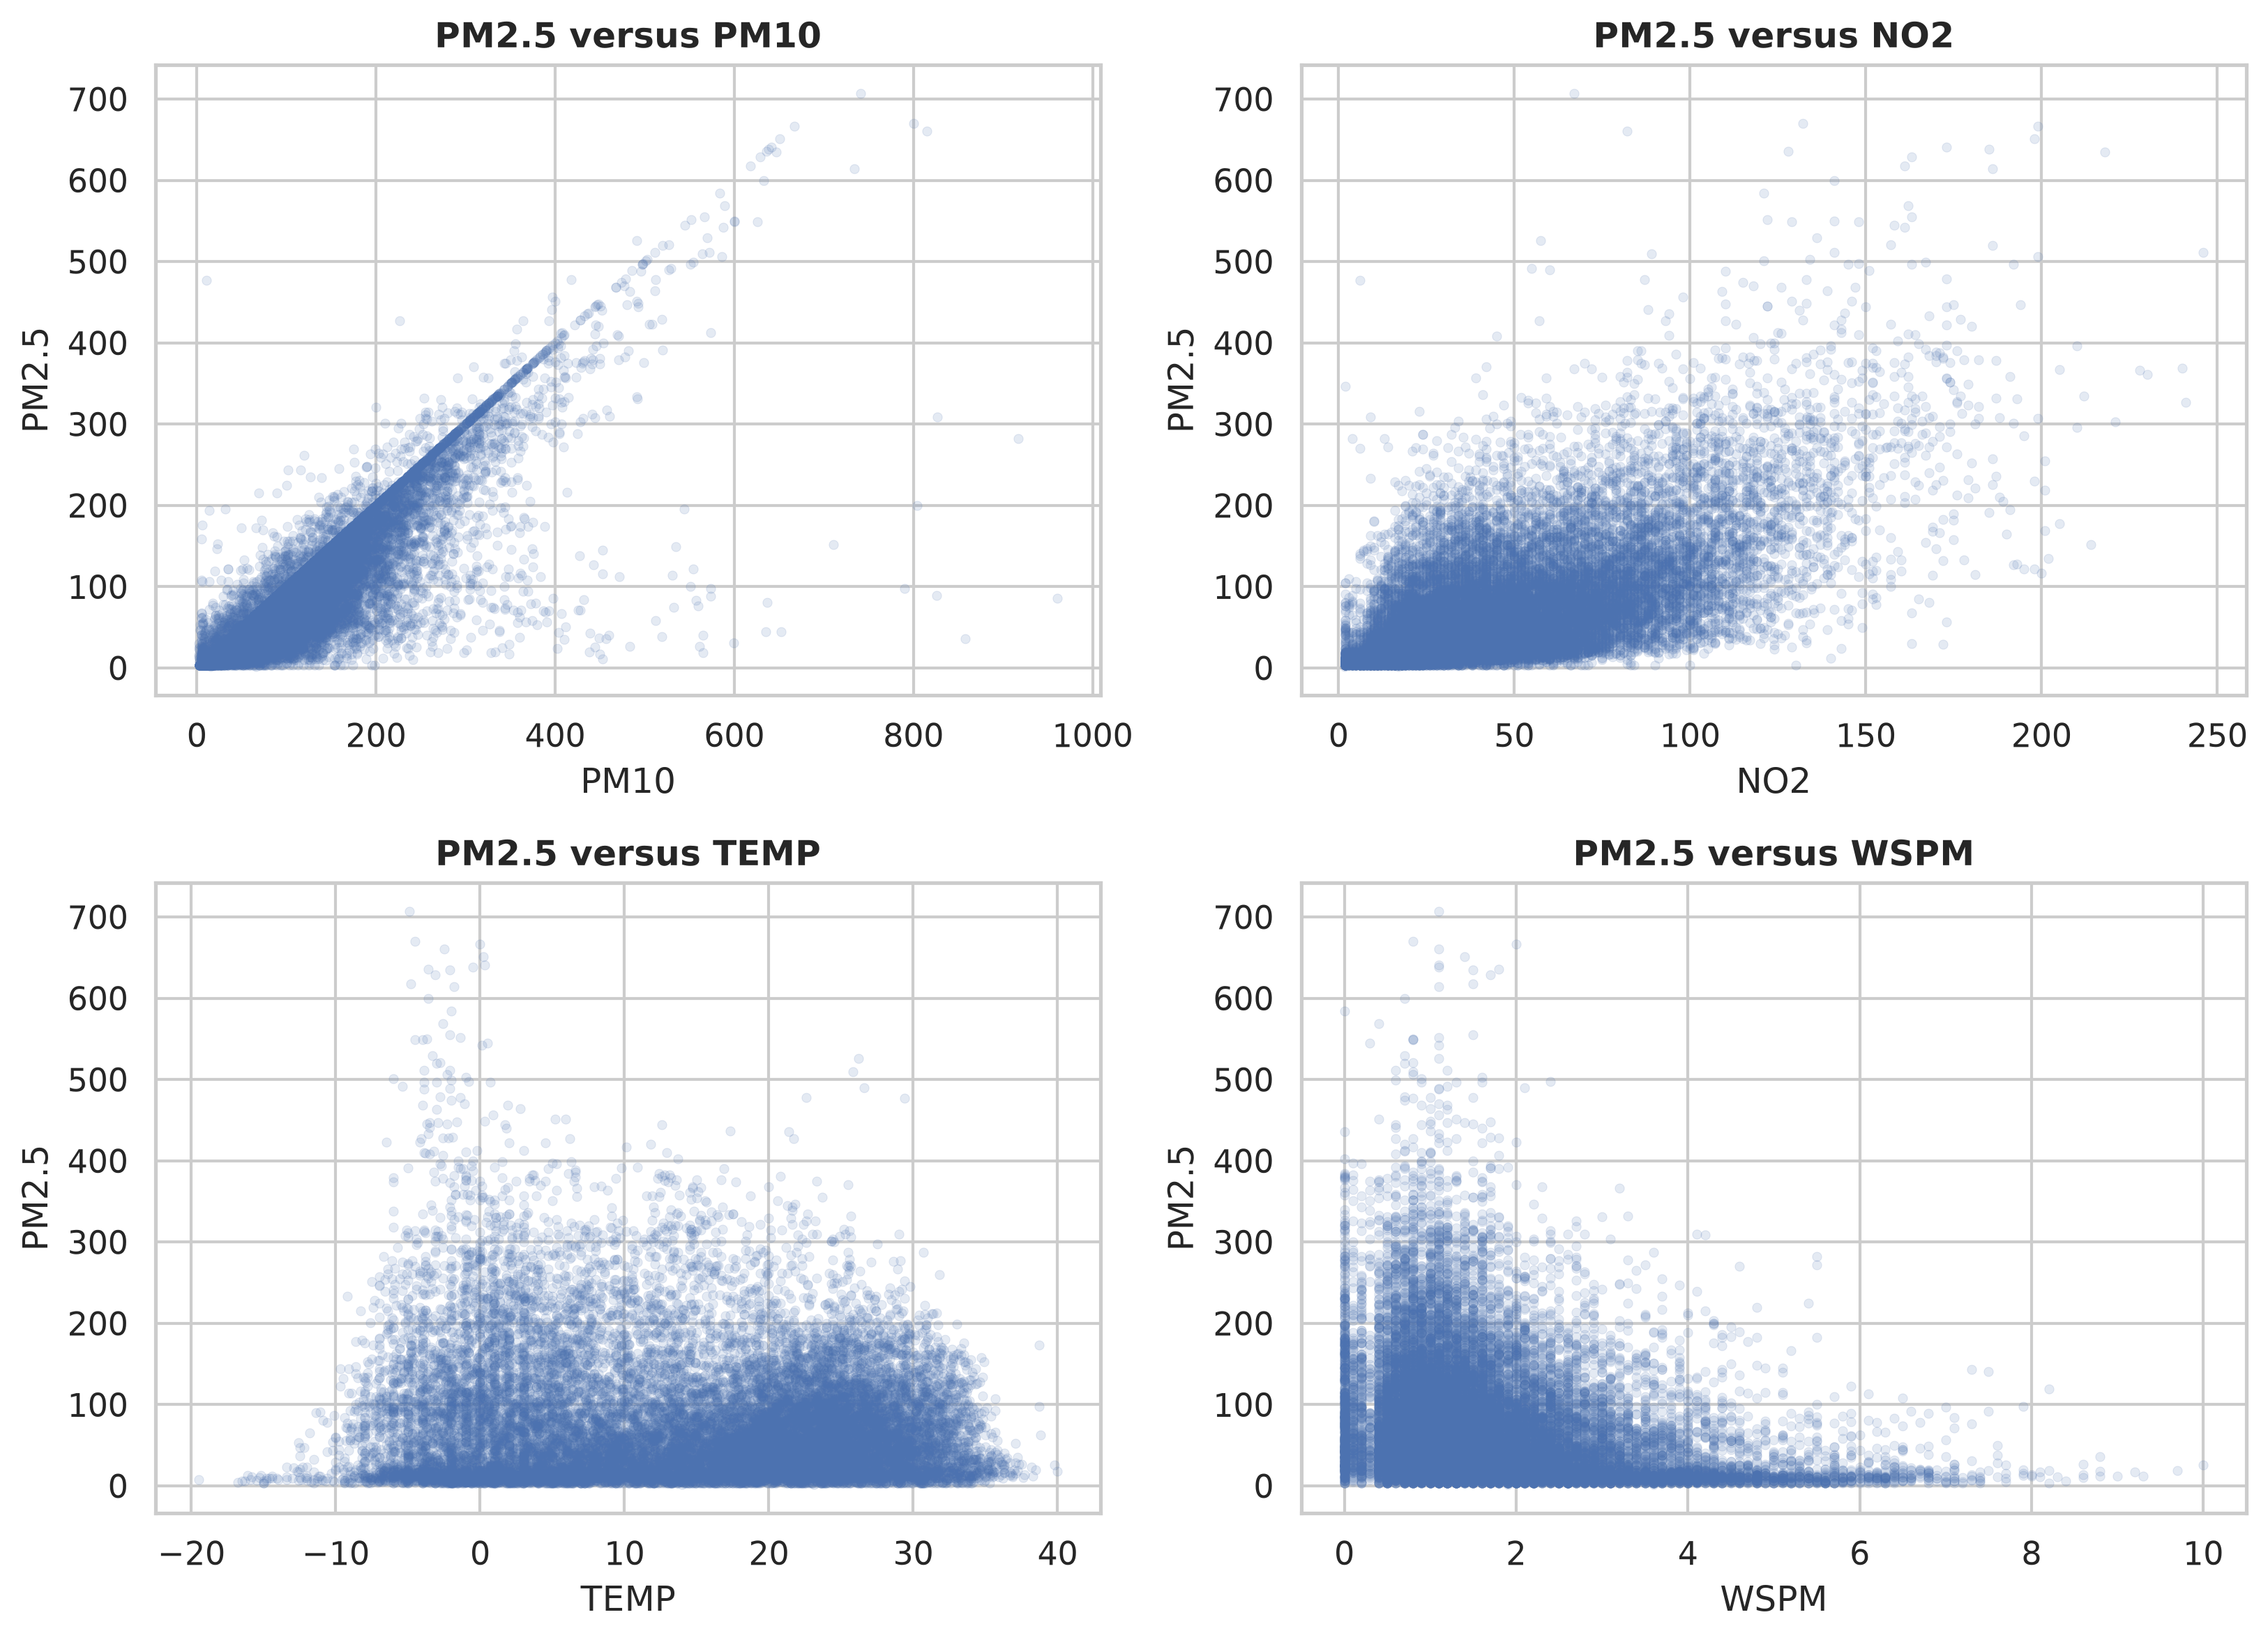

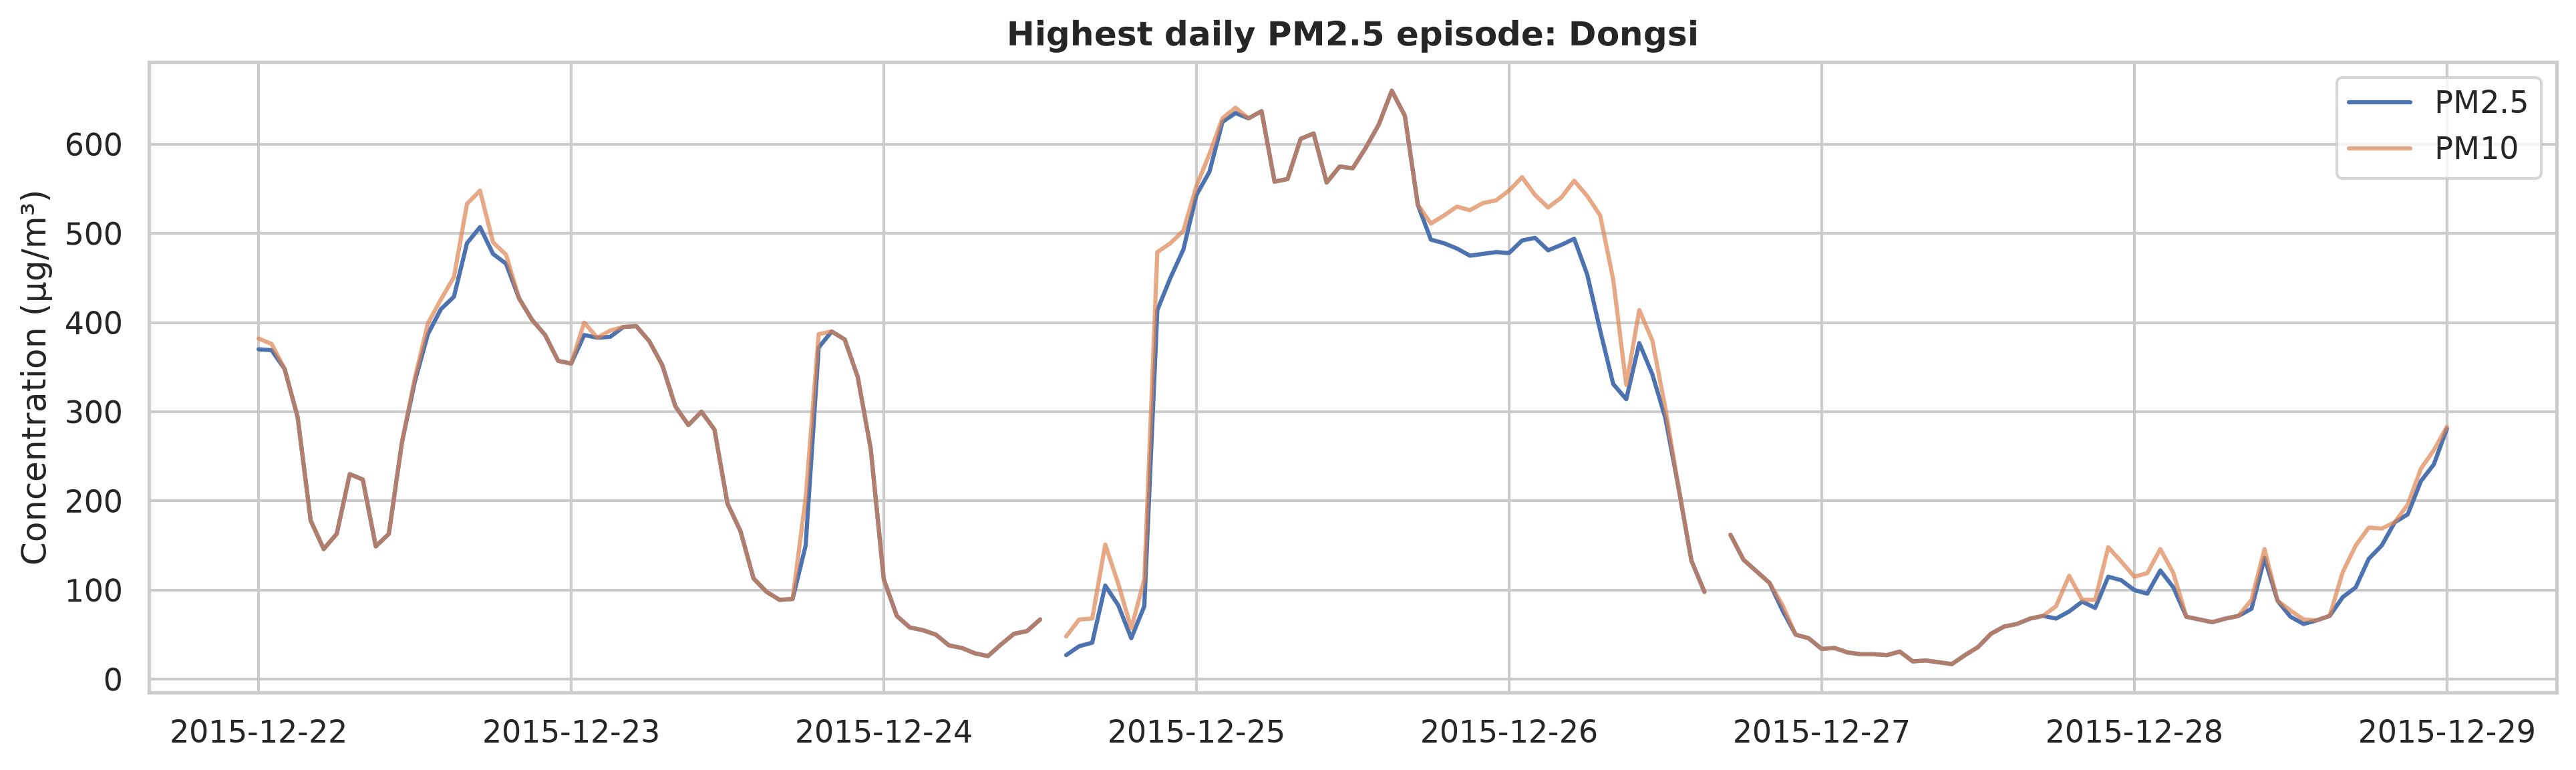

In [5]:
display(Image(filename=str(PATHS.assignment1_figures / "pm25_temporal_patterns.png")))
display(Image(filename=str(
    PATHS.assignment1_figures / "continuous_correlation_heatmap.png"
)))
display(Image(filename=str(PATHS.assignment1_figures / "pm25_autocorrelation.png")))
display(Image(filename=str(
    PATHS.assignment1_figures / "pm25_feature_relationships.png"
)))
display(Image(filename=str(
    PATHS.assignment1_figures / "selected_pollution_episode.png"
)))


## Leakage-safe preprocessing and chronological splits

**Decision.** Use capped causal forward filling, training-only station/global medians,
training-fitted scaling, and target-time chronological splits. **Alternatives.** Random
splitting leaks future regimes; unrestricted filling can freeze a sensor for weeks;
interpolation can use future values. **Evidence.** The missing-run table includes long
pollutant gaps. V2.2 retains the V2.1 validation-selected 24-hour fill cap and 12-hour
lookback, then compares three causal feature policies over repeated-seed expanding
folds. **Support.** Rolling evaluation respects forecasting order
([Bergmeir et al.](https://doi.org/10.1016/j.csda.2017.11.003)). **Trade-off.** Median
fallback is robust but smooths unusual conditions. Targets retain original, unfilled
measurements and splits are assigned by target timestamp.


{'features': ['z__PM2.5',
  'z__PM10',
  'z__SO2',
  'z__NO2',
  'z__CO',
  'z__O3',
  'z__TEMP',
  'z__PRES',
  'z__DEWP',
  'z__RAIN',
  'z__WSPM',
  'missing__PM2.5',
  'missing__PM10',
  'missing__SO2',
  'missing__NO2',
  'missing__CO',
  'missing__O3',
  'missing__TEMP',
  'missing__PRES',
  'missing__DEWP',
  'missing__RAIN',
  'missing__WSPM',
  'hour_sin',
  'hour_cos',
  'doy_sin',
  'doy_cos',
  'wind_sin',
  'wind_cos',
  'wind_missing',
  'station__Aotizhongxin',
  'station__Changping',
  'station__Dingling',
  'station__Dongsi',
  'station__Guanyuan',
  'station__Gucheng',
  'station__Huairou',
  'station__Nongzhanguan',
  'station__Shunyi',
  'station__Tiantan',
  'station__Wanliu',
  'station__Wanshouxigong'],
 'count': 41,
 'feature_policy': 'base',
 'engineered_features': []}

{'methodology_version': 'v2.2-focused-lstm-2026-08',
 'source_fingerprint': 'c9c4e3812d15bff6e6cf7737963fb968a0f31ba6130ab364434d62d892fdac46',
 'lookback_hours': 12,
 'forward_fill_limit_hours': 24,
 'forecast_horizon': 1,
 'feature_policy': 'base',
 'engineered_features': [],
 'feature_count': 41,
 'features': ['z__PM2.5',
  'z__PM10',
  'z__SO2',
  'z__NO2',
  'z__CO',
  'z__O3',
  'z__TEMP',
  'z__PRES',
  'z__DEWP',
  'z__RAIN',
  'z__WSPM',
  'missing__PM2.5',
  'missing__PM10',
  'missing__SO2',
  'missing__NO2',
  'missing__CO',
  'missing__O3',
  'missing__TEMP',
  'missing__PRES',
  'missing__DEWP',
  'missing__RAIN',
  'missing__WSPM',
  'hour_sin',
  'hour_cos',
  'doy_sin',
  'doy_cos',
  'wind_sin',
  'wind_cos',
  'wind_missing',
  'station__Aotizhongxin',
  'station__Changping',
  'station__Dingling',
  'station__Dongsi',
  'station__Guanyuan',
  'station__Gucheng',
  'station__Huairou',
  'station__Nongzhanguan',
  'station__Shunyi',
  'station__Tiantan',
  'station__W

,count,mean,median,std,min,max
split,,,,,,
train,292006,81.869727,58.0,80.169155,2.0,844.0
validation,59962,64.329725,45.0,67.255427,3.0,999.0


{'forward_fill_limit_hours': 24,
 'lookback_hours': 12,
 'basis': 'V2.1 rolling-validation ablations; held fixed for focused V2.2',
 'source_fingerprint': 'c9c4e3812d15bff6e6cf7737963fb968a0f31ba6130ab364434d62d892fdac46'}

,candidate_id,mean_mae,std_mae,folds,mean_seed_std_mae,min_seeds_per_fold,max_seeds_per_fold,evaluations,mean_best_epoch,median_best_epoch,parameters,num_layers,formulation,se_mae,feature_policy,complexity_rank
0,multivariate_dynamics,9.097275,0.585614,3,0.042794,2,2,6,13.000000,12.5,35649,1,direct,0.338104,multivariate_dynamics,2
1,pm25_dynamics,9.098801,0.573091,3,0.048341,2,2,6,10.833333,9.5,33089,1,direct,0.330874,pm25_dynamics,1
2,base,9.114682,0.595679,3,0.032644,2,2,6,7.833333,7.0,29249,1,direct,0.343915,base,0


,candidate_id,raw_winner,mean_paired_degradation,paired_standard_error,paired_one_se_eligible,paired_folds
0,multivariate_dynamics,multivariate_dynamics,0.000000,0.000000,True,3
1,pm25_dynamics,multivariate_dynamics,0.001526,0.024053,True,3
2,base,multivariate_dynamics,0.017407,0.018068,True,3


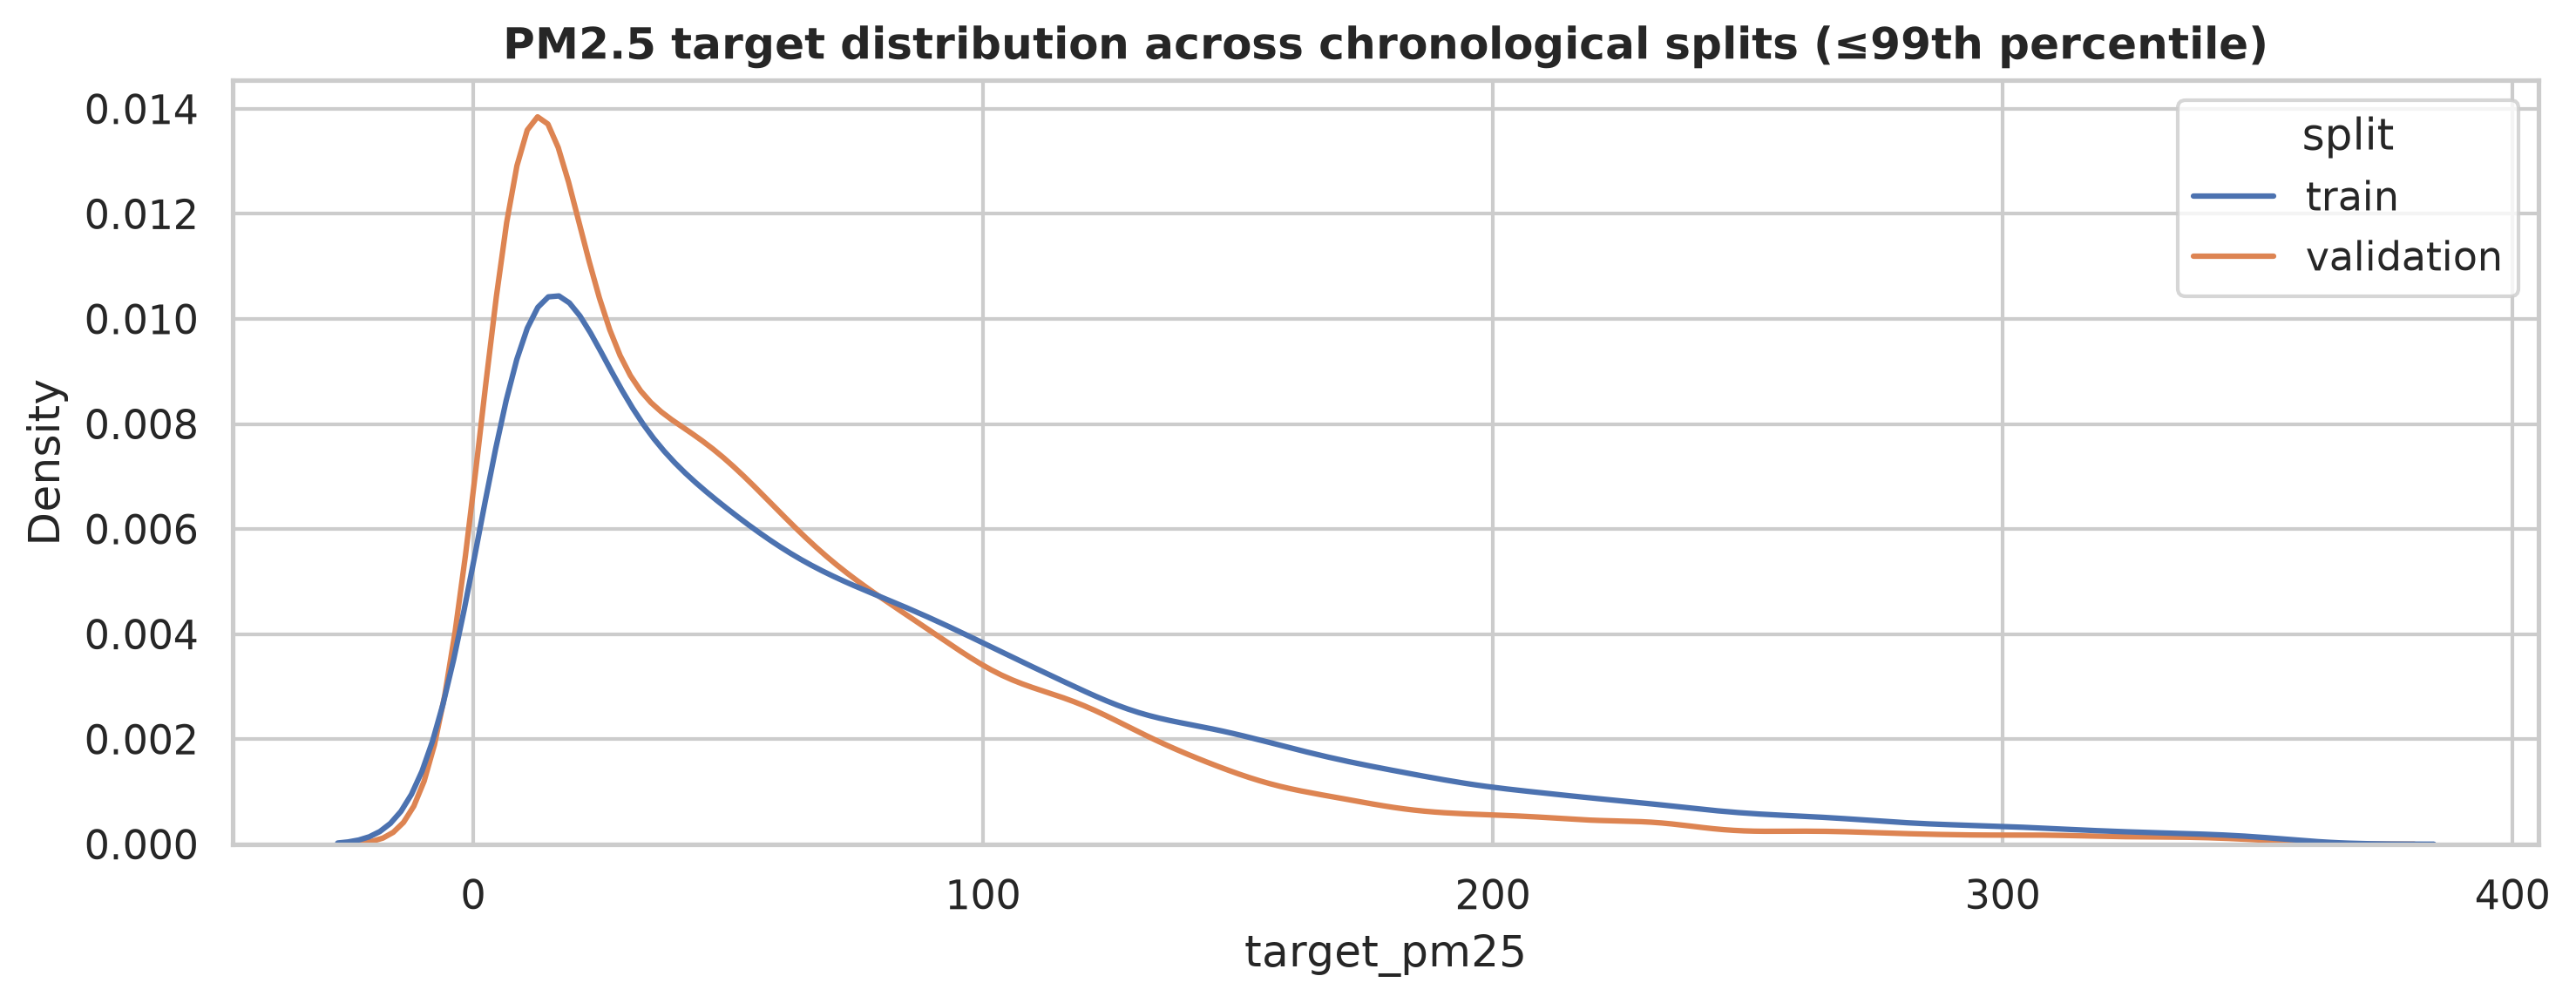

EDA and causal preprocessing complete.


In [6]:
suffix = OPTIONS.artifact_suffix
feature_metadata = json.loads(
    (PATHS.processed / f"feature_metadata{suffix}.json").read_text(encoding="utf-8")
)
split_metadata = json.loads(
    (PATHS.processed / f"split_metadata{suffix}.json").read_text(encoding="utf-8")
)
split_distribution = pd.read_csv(
    PATHS.assignment1_tables / "target_distribution_by_split.csv", index_col=0
)
preprocessing_lock = json.loads(
    (PATHS.processed / f"preprocessing_lock{suffix}.json").read_text(encoding="utf-8")
)
feature_ablation = pd.read_csv(
    PATHS.assignment2_tables / f"feature_policy_ablation_summary{suffix}.csv"
)
feature_audit = pd.read_csv(
    PATHS.assignment2_tables / f"feature_policy_paired_audit{suffix}.csv"
)
display(feature_metadata)
display(split_metadata)
display(split_distribution)
display(preprocessing_lock)
display(feature_ablation)
display(feature_audit)
display(Image(filename=str(
    PATHS.assignment1_figures / "target_distribution_by_split.png"
)))
print("EDA and causal preprocessing complete.")
